### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_NMSCYHFAAKNK


### Main

In [3]:
# mapping from the second recording to the first recording
roi_mapping_json = "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec8/roi_mapping.json"
inverse_roi_mapping = False

database = [
    {
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec9/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec8/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec8/ROI_transformed_corrected.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec8/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
]

savedir = "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec8-rec9"

### Import stuff

In [4]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import ndimage as ndi
import h5py
import json
from scipy.signal import chirp
from scipy.stats import pearsonr, spearmanr

import sys
sys.path.append("../")
from monitor_flip_functions import compute_qi_custom, compute_response_index, make_plot

In [5]:
from matplotlib import font_manager
import matplotlib as mpl

font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [6]:
# mapping from second recording to the first recording!
with open(roi_mapping_json, "r", encoding="utf-8") as f:
    roi_mapping = json.load(f)
roi_mapping = {int(k): v for k, v in roi_mapping.items()}

if inverse_roi_mapping:
    # swap key and values (inverse map)
    roi_mapping = {v: k for k, v in roi_mapping.items()}

In [7]:
E1 = []
for (k, d) in enumerate(database):
    with pd.HDFStore(d["resp_table"], mode='r') as store:
        e = store["E"]
    e["recording"] = k
    e = e.reset_index().set_index(["recording", "neuron", "session", "trial", "time"])
    E1.append(e)
E1 = pd.concat(E1)

In [8]:
# merge two recordings
E = []
for nid1 in E1.xs(1, level="recording").index.get_level_values("neuron").unique():
    if nid1 in roi_mapping.keys():
        nid0 = roi_mapping[nid1]
    else:
        continue
    if nid0 is None:
        continue

    e0 = E1.xs((0, nid0), level=("recording", "neuron")).copy()
    e0.reset_index(inplace=True)

    e1 = E1.xs((1, nid1), level=("recording", "neuron")).copy()
    e1.reset_index(inplace=True)
    e1["session"] = e1["session"].replace({0: 3, 1: 4, 2: 5})

    e = pd.concat([e0, e1])
    e["neuron"] = nid0
    e.set_index(["neuron", "session", "trial", "time"], inplace=True)

    E.append(e)
E = pd.concat(E)

In [9]:
display(E)

y
neuron session trial time            
0      0       0     -2000  -1.566126
                     -1950  -1.850552
                     -1900  -1.022197
                     -1850  -1.080155
                     -1800   0.004882
...                               ...
165    5       9      18750  0.983641
                      18800 -1.178742
                      18850 -0.666483
                      18900  0.625293
                      18950 -0.998466

[4183200 rows x 1 columns]

In [10]:
with pd.HDFStore(os.path.join(tmpdir, "response_table_combined.hdf5"), mode='w') as store:
    store.put('E', E)

In [11]:
dt = 1e-2
stimulus = np.zeros(int(21.0/dt), dtype=np.float32)
stimulus[0:int(2.0/dt)] = 0
stimulus[int(2.0/dt):int(6.0/dt)] = 1
stimulus[int(6.0/dt):int(10.0/dt)] = 0
stimulus[int(10.0/dt):int(12.0/dt)] = 0.5
stimulus[int(12.0/dt):int(20.0/dt)] = 0.5 + 0.5 * chirp(np.linspace(0, 8, int(20.0/dt)-int(12.0/dt)), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
stimulus[int(20.0/dt):int(21.0/dt)] = 0

In [ ]:
scores = []

for nid in E.index.get_level_values("neuron").unique().sort_values():
    q1 = compute_qi_custom(E, nid, 2)
    q2 = compute_qi_custom(E, nid, 5)

    df1 = E.xs((2, nid), level=["session", "neuron"])
    mat1 = df1.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
    y1 = np.nanmean(mat1, axis=0)
    y1 = y1[:200]

    df2 = E.xs((5, nid), level=["session", "neuron"])
    mat2 = df2.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
    y2 = np.nanmean(mat2, axis=0)
    y2 = y2[:200]

    r1 = compute_response_index(y1, cutoff=0.08, fs=20)
    r2 = compute_response_index(y2, cutoff=0.08, fs=20)

    pearson, pval = pearsonr(y1, y2)
    spearman, pval = spearmanr(y1, y2)

    cond1 = q1 > 0.25 and r1 > 0.6
    cond2 = q2 > 0.25 and r2 > 0.6

    if cond1 or cond2:
        print(nid)
        print(f"{q1:.3f}", f"{q2:.3f}")
        print(f"{r1:.3f}", f"{r2:.3f}")
        print("Pearson correlation", f"{pearson:.3f}")
        print("Spearman correlation", f"{spearman:.3f}")
        make_plot(E, nid, stimulus,  vmin=-2, vmax=3,  cmap_name="inferno", )
        fig, ax = plt.subplots(figsize=(1.5,1.5))
        ax.scatter(y1, y2, s=1)
        plt.show()
        scores.append(pearson)

scores = np.array(scores)
print(scores.size)

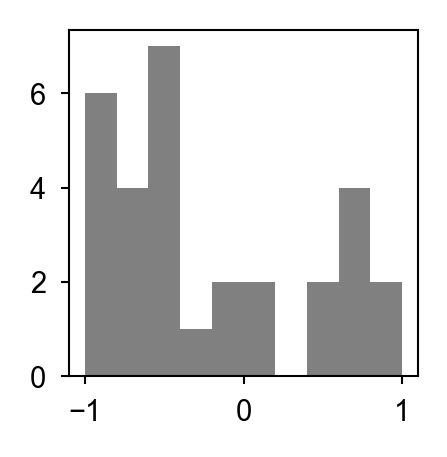

In [13]:
fig, ax = plt.subplots(figsize=(1.5, 1.5), dpi=300)

count, bin_edges = np.histogram(scores, range=[-1,1], bins=10, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], align="center", lw=0, color="gray")
ax.set_xlim(-1.1,1.1)
plt.show()

### Copy data to bucket

In [14]:
import subprocess

In [15]:
cmd1 = f'ssh deigo "mkdir -p {savedir}"'
cmd2 = f'ssh deigo "cp -r {tmpdir}/* {savedir}"'
print(cmd1)
print(cmd2)

subprocess.run(cmd1, shell=True, check=True)
subprocess.run(cmd2, shell=True, check=True)

ssh deigo "mkdir -p /bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec8-rec9"
ssh deigo "cp -r /flash/ReiterU/tmp/tomo_NMSCYHFAAKNK/* /bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec8-rec9"


Offending key for IP in /home/t/tomoyuki-mano1/.ssh/known_hosts:1
Matching host key in /home/t/tomoyuki-mano1/.ssh/known_hosts:6


CompletedProcess(args='ssh deigo "cp -r /flash/ReiterU/tmp/tomo_NMSCYHFAAKNK/* /bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec8-rec9"', returncode=0)